# Phase 9: τ²-bench telecom, compare the three arms + free airline check

**Goal:** the statistics for the telecom arms of 12, done the same way as 10 for airline. **No new runs, no API cost, CPU only.** This notebook only reads the saved dialogues.

| Part | What it measures | Cell |
|---|---|---|
| 1 | pass^k for k = 1..8 with 95% bootstrap CI, and the curve | 5–6 |
| 2 | **Paired Δ** over the same 40 tasks: shallow vs validator (Hypothesis 1), shallow vs baseline, validator vs baseline | 7 |
| 3 | Task consistency: always / never / sometimes pass | 8 |
| 4 | pass^1 by **issue type** (MMS, service, mobile data), user persona, and number of planted faults | 9 |
| 5 | **Why dialogues fail:** how they end, failure category, which end-state check failed, how many user-side fixes were done | 10 |
| 6 | **Policy violations:** replay every dialogue and count calls that broke one of the 5 validator rules and really ran; violations inside *passing* dialogues (hidden by the score) | 11 |
| 7 | **Hand-check** of 15 failed dialogues (5 per arm): agent, simulator, benchmark, or unclear? | 12–13 |
| 8 | **Free airline check:** run my airline validator on τ²-bench's *airline* answer keys. Are the 8 label conflicts from τ-bench (tasks 10, 16, 19, 26, 27, 34, 45, 46) still there? | 14 |

**How the score works in telecom:** a dialogue passes only if the phone ends in the right state (`ENV_ASSERTION`, e.g. "can send MMS"), and for some tasks the agent must also take one required action (`ACTION`, e.g. transfer to a human). The list of user-side fixes (`action_checks` with requestor = user) is **not** part of the score; I use it only to see how far the agent got.

**Statistics:** same as 10. pass^k per task = C(c, k) / C(n, k); 95% CI = 2,000 bootstrap samples over tasks (seed 0); paired Δ uses the same task samples for both arms; **\*** = the CI does not include 0.

**Outputs** (in `results_compare_tau2/` and `figures/`):

| File | Content |
|---|---|
| `dialogues.csv` | one row per dialogue (960): result, issue type, user fixes, blocks, violations |
| `passk_all_arms.csv` | pass^k with CI for k = 1..8 |
| `paired_tests.csv` | paired Δ with CI |
| `handcheck/*.md`, `handcheck_labels.csv` | the 15 dialogues to read and the label sheet (not overwritten once it exists) |
| `figures/telecom_passk.png` | pass^k curves |

**Runtime:** CPU, about 2–3 minutes (the replay in cell 4 takes the longest).

**Run first:** 12 (all three arms finished). Part 8 also needs the airline project folder `cmsc691-10-project2` (from 01–06G).



In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# re-install tau2-bench from the clone made in 11 (a new Colab runtime forgets installs)
%cd /content/drive/MyDrive/cmsc691-10-tau2/tau2-bench
!git log -1 --format="tau2-bench commit %h"
!pip install -q -e .
print("installed")

/content/drive/MyDrive/cmsc691-10-tau2/tau2-bench
tau2-bench commit da0835f
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau2 (pyproject.toml) ... done
installed


In [7]:
%%writefile /content/drive/MyDrive/cmsc691-10-tau2/compare_tau2.py
# Compare the tau2-bench telecom arms (baseline, validator, shallow KiL) from saved results only.
# No API calls. Same statistics as the airline notebook 10: pass^k per task (tau-bench formula),
# 95% bootstrap CI over tasks, paired differences over the same tasks.
import random
import re
from collections import Counter
from math import comb

import pandas as pd

ARMS = ["baseline", "validator", "shallow"]
ISSUES = ["mms_issue", "service_issue", "mobile_data_issue"]
BLOCK_TAG = "BLOCKED by policy validator"


# ------------------------------------------------------------------ task id parts
def issue(task_id):
    return task_id.split("]")[0].strip("[")


def persona(task_id):
    m = re.search(r"PERSONA:(\w+)", task_id)
    return m.group(1) if m else "None"


def n_faults(task_id):
    """Number of problems planted on the phone / account, e.g. airplane_mode_on|bad_vpn -> 2."""
    return len(task_id.split("]")[1].split("[")[0].split("|"))


# ------------------------------------------------------------------ one row per dialogue
def auto_category(ri, end):
    """A simple first guess of why a failed dialogue failed (checked by hand later)."""
    if end == "max_steps":
        return "ran out of steps"
    if end == "too_many_errors":
        return "too many tool errors"
    acts = ri.get("action_checks") or []
    if any(a["action"]["requestor"] == "assistant" and not a["action_match"] for a in acts):
        return "agent action missing or wrong"
    if any(a["action"]["requestor"] == "user" and not a["action_match"] for a in acts):
        return "user fix not done"
    return "phone state not reached"


def dialogue_rows(arm, res, replay=None):
    """res = Results from tau2 (pydantic). replay(sim, task) -> dict of executed violations by rule."""
    tasks = {t.id: t for t in res.tasks}
    out = []
    for s in res.simulations:
        ri = s.reward_info.model_dump() if s.reward_info else {}
        end = getattr(s.termination_reason, "value", s.termination_reason)
        acts = ri.get("action_checks") or []
        need_user = [a for a in acts if a["action"]["requestor"] == "user"]
        need_agent = [a for a in acts if a["action"]["requestor"] == "assistant"]
        failed = [e["env_assertion"]["func_name"] for e in (ri.get("env_assertions") or []) if not e["met"]]
        msgs = s.messages or []
        row = {
            "arm": arm, "task": s.task_id, "trial": s.trial,
            "issue": issue(s.task_id), "persona": persona(s.task_id), "faults": n_faults(s.task_id),
            "passed": (ri.get("reward") or 0) >= 1 - 1e-6, "end": end,
            "agent msgs": sum(m.role == "assistant" for m in msgs),
            "agent tool calls": sum(len(m.tool_calls or []) for m in msgs if m.role == "assistant"),
            "user tool calls": sum(len(m.tool_calls or []) for m in msgs if m.role == "user"),
            "user fixes needed": len(need_user), "user fixes done": sum(a["action_match"] for a in need_user),
            "agent actions needed": len(need_agent), "agent actions done": sum(a["action_match"] for a in need_agent),
            "failed checks": ", ".join(failed),
            "blocked": sum(1 for m in msgs if m.role == "tool" and BLOCK_TAG in str(m.content)),
            "blocked rules": ", ".join(r for m in msgs if m.role == "tool" and BLOCK_TAG in str(m.content)
                                       for r in re.findall(r"\[(\w\d)\]", str(m.content))),
        }
        row["category"] = "" if row["passed"] else auto_category(ri, end)
        if replay:
            v = replay(s, tasks[s.task_id])
            row["violations executed"] = sum(v.values())
            row["violated rules"] = ", ".join(f"{r} x{n}" for r, n in sorted(v.items()))
        out.append(row)
    return pd.DataFrame(out)


def make_replay(make_env, violations, checked):
    """Replay each dialogue's tool calls in a fresh environment and count the calls that broke a
    validator rule and were really executed (calls the validator rejected are skipped, as in tau2)."""
    def replay(sim, task):
        env = make_env()
        env.set_state(initialization_data=task.initial_state.initialization_data,
                      initialization_actions=task.initial_state.initialization_actions, message_history=[])
        status = {m.id: m.execution_status for m in sim.messages if m.role == "tool"}
        found = Counter()
        for m in sim.messages:
            for tc in (m.tool_calls or []) if m.role in ("assistant", "user") else []:
                if status.get(tc.id) == "rejected":
                    continue
                if tc.requestor == "assistant" and tc.name in checked:
                    for rule, _ in violations(env.tools, tc.name, tc.arguments or {}):
                        found[rule] += 1
                try:
                    env.get_response(tc)
                except Exception:
                    pass
        return dict(found)
    return replay


# ------------------------------------------------------------------ pass^k and bootstrap
def task_counts(df):
    g = df.groupby("task")["passed"].agg(["sum", "count"])
    return {t: (int(c), int(n)) for t, (c, n) in g.iterrows()}


def passk_tasks(counts, k):
    return {t: comb(c, k) / comb(n, k) for t, (c, n) in counts.items() if n >= k}


def curve(df, max_k=8, reps=2000, seed=0):
    counts = task_counts(df)
    tasks = sorted(counts)
    rng = random.Random(seed)
    samples = [[rng.choice(tasks) for _ in tasks] for _ in range(reps)]
    rows = []
    for k in range(1, max_k + 1):
        per = passk_tasks(counts, k)
        boot = sorted(sum(per[t] for t in s) / len(s) for s in samples)
        rows.append({"k": k, "pass^k": sum(per.values()) / len(per),
                     "ci_low": boot[int(0.025 * reps)], "ci_high": boot[int(0.975 * reps) - 1]})
    return pd.DataFrame(rows)


def paired(df_a, df_b, ks=(1, 2, 4, 8), reps=2000, seed=0):
    """Δ = arm a − arm b over the same tasks, 95% bootstrap CI; * = CI excludes 0."""
    ca, cb = task_counts(df_a), task_counts(df_b)
    tasks = sorted(set(ca) & set(cb))
    rng = random.Random(seed)
    samples = [[rng.choice(tasks) for _ in tasks] for _ in range(reps)]
    out = {}
    for k in ks:
        pa, pb = passk_tasks(ca, k), passk_tasks(cb, k)
        d = {t: pa[t] - pb[t] for t in tasks}
        boot = sorted(sum(d[t] for t in s) / len(s) for s in samples)
        lo, hi = boot[int(0.025 * reps)], boot[int(0.975 * reps) - 1]
        out[k] = (sum(d.values()) / len(d), lo, hi, lo > 0 or hi < 0)
    return out


def fmt_delta(x):
    d, lo, hi, sig = x
    return f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if sig else "")


def consistency(df):
    c = df.groupby("task")["passed"].agg(["sum", "count"])
    return {"always pass": int((c["sum"] == c["count"]).sum()), "never pass": int((c["sum"] == 0).sum()),
            "sometimes": int(((c["sum"] > 0) & (c["sum"] < c["count"])).sum())}


# ------------------------------------------------------------------ hand-check export
def pick_failed(df, arm, n=5, seed=0):
    """n failed dialogues of one arm, spread over the three issue types, at most one per task."""
    f = df[(df.arm == arm) & ~df.passed].sample(frac=1, random_state=seed)
    picked, tasks = [], set()
    while len(picked) < n:
        added = False
        for iss in ISSUES:                       # round robin over issue types
            rows = f[(f.issue == iss) & ~f.task.isin(tasks)]
            if len(rows) and len(picked) < n:
                picked.append(rows.iloc[0]); tasks.add(rows.iloc[0].task); added = True
        if not added:
            break
    return pd.DataFrame(picked)


def transcript_md(sim, row, max_tool=300):
    lines = [f"# {row['arm']} | trial {row['trial']} | {row['task']}", "",
             f"- **Result:** {'PASS' if row['passed'] else 'FAIL'} ; ends: {row['end']} ; auto category: {row['category']}",
             f"- **Failed checks:** {row['failed checks'] or '-'}",
             f"- **User fixes done:** {row['user fixes done']} / {row['user fixes needed']} ; "
             f"**agent actions done:** {row['agent actions done']} / {row['agent actions needed']}",
             f"- **Blocked by validator:** {row['blocked']} {('(' + row['blocked rules'] + ')') if row['blocked'] else ''}",
             "", "---", ""]
    for m in sim.messages or []:
        who = {"assistant": "AGENT", "user": "USER", "tool": "TOOL"}.get(m.role, m.role.upper())
        if m.role == "tool":
            txt = str(m.content or "")
            lines.append(f"> **{who}** ({getattr(m, 'requestor', '')}): {txt[:max_tool]}{' …' if len(txt) > max_tool else ''}")
        else:
            if m.content:
                lines.append(f"**{who}:** {m.content}")
            for tc in m.tool_calls or []:
                lines.append(f"**{who} → `{tc.name}`** `{tc.arguments}`")
        lines.append("")
    return "\n".join(lines)

Overwriting /content/drive/MyDrive/cmsc691-10-tau2/compare_tau2.py


In [8]:
# 4. load the three arms and build one table with one row per dialogue (replay takes about 1 minute)
import os, sys, json, importlib, logging
import pandas as pd
os.environ["TAU2_DATA_DIR"] = "/content/drive/MyDrive/cmsc691-10-tau2/tau2-bench/data"
sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-tau2")
sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-tau2/tau2-bench/src")      # the editable install is only seen after a restart
logging.disable(logging.WARNING)
from loguru import logger; logger.remove()
from tau2.data_model.simulation import Results
from tau2.registry import registry
import analyze_tau2 as A, validator_tau2 as V, compare_tau2 as C
for m in (A, V, C): importlib.reload(m)

SIM, OUT, FIG = "/content/drive/MyDrive/cmsc691-10-tau2/tau2-bench/data/simulations", "/content/drive/MyDrive/cmsc691-10-tau2/results_compare_tau2", "/content/drive/MyDrive/cmsc691-10-tau2/figures"
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)
R = {a: Results.load(f"{SIM}/telecom_{a}/results.json") for a in C.ARMS}
replay = C.make_replay(registry.get_env_constructor("telecom"), V.violations, V.CHECKED)
df = pd.concat([C.dialogue_rows(a, R[a], replay) for a in C.ARMS], ignore_index=True)
df.to_csv(f"{OUT}/dialogues.csv", index=False)
D = {a: df[df.arm == a] for a in C.ARMS}

A.show(pd.DataFrame([{"arm": a, "dialogues": len(d), "tasks": d.task.nunique(), "trials / task": int(d.groupby("task").size().min()),
                      "pass^1": d.passed.mean(), "user tool calls": d["user tool calls"].mean(),
                      "agent msgs": d["agent msgs"].mean(), "blocked calls": int(d.blocked.sum()),
                      "violations executed": int(d["violations executed"].sum())} for a, d in D.items()]),
       "Telecom arms (from saved dialogues)", fmt={"pass^1": "{:.3f}", "user tool calls": "{:.1f}", "agent msgs": "{:.1f}"},
       bar=["pass^1"])

arm,dialogues,tasks,trials / task,pass^1,user tool calls,agent msgs,blocked calls,violations executed
baseline,320,40,8,0.312,2.5,20.1,0,48
validator,320,40,8,0.316,2.4,19.1,45,0
shallow,320,40,8,0.434,4.5,18.7,0,38


In [9]:
# 5. pass^k for k = 1..8 with 95% bootstrap CI over tasks
curves = {a: C.curve(d) for a, d in D.items()}
tab = pd.DataFrame({"k": range(1, 9)})
for a, c in curves.items():
    tab[a] = [f"{p:.3f} [{lo:.2f}, {hi:.2f}]" for p, lo, hi in zip(c["pass^k"], c.ci_low, c.ci_high)]
tab.to_csv(f"{OUT}/passk_all_arms.csv", index=False)
A.show(tab, "pass^k [95% CI]")
A.show(pd.DataFrame([{"arm": a, "pass^1": c["pass^k"].iloc[0], "pass^8": c["pass^k"].iloc[7],
                      "drop 1→8": 1 - c["pass^k"].iloc[7] / c["pass^k"].iloc[0]} for a, c in curves.items()]),
       "Curve shape (Hypothesis 1 asks for a flatter curve = smaller drop)",
       fmt={"pass^1": "{:.3f}", "pass^8": "{:.3f}", "drop 1→8": "{:.0%}"}, bar=["pass^1", "pass^8"])

k,baseline,validator,shallow
1,"0.312 [0.19, 0.44]","0.316 [0.19, 0.44]","0.434 [0.31, 0.56]"
2,"0.255 [0.13, 0.38]","0.260 [0.14, 0.38]","0.334 [0.21, 0.46]"
3,"0.233 [0.12, 0.35]","0.230 [0.12, 0.35]","0.289 [0.17, 0.41]"
4,"0.216 [0.10, 0.34]","0.206 [0.10, 0.32]","0.259 [0.14, 0.38]"
5,"0.202 [0.09, 0.32]","0.184 [0.08, 0.30]","0.235 [0.12, 0.35]"
6,"0.190 [0.08, 0.31]","0.163 [0.07, 0.28]","0.213 [0.11, 0.33]"
7,"0.181 [0.07, 0.30]","0.144 [0.05, 0.26]","0.194 [0.09, 0.32]"
8,"0.175 [0.07, 0.30]","0.125 [0.03, 0.25]","0.175 [0.07, 0.30]"


arm,pass^1,pass^8,drop 1→8
baseline,0.312,0.175,44%
validator,0.316,0.125,60%
shallow,0.434,0.175,60%


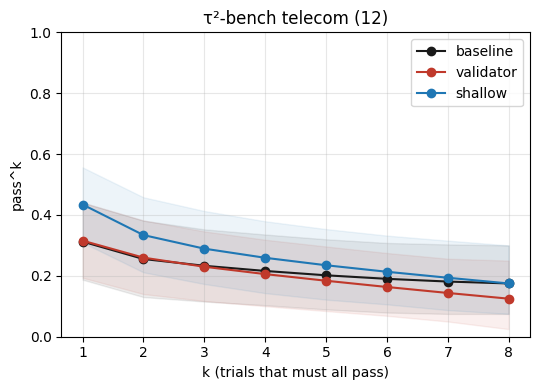

In [10]:
# 6. figure: pass^k curves with 95% CI (same colors as the airline figure in 10)
import matplotlib.pyplot as plt
COL = {"baseline": "#1A1A1A", "validator": "#C0392B", "shallow": "#1F77B4"}
fig, ax = plt.subplots(figsize=(5.5, 4))
for a, c in curves.items():
    ax.fill_between(c.k, c.ci_low, c.ci_high, alpha=0.08, color=COL[a])
    ax.plot(c.k, c["pass^k"], "o-", color=COL[a], label=a)
ax.set_title("τ²-bench telecom (12)"); ax.set_xlabel("k (trials that must all pass)"); ax.set_ylabel("pass^k")
ax.set_xticks(range(1, 9)); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/telecom_passk.png", dpi=200, bbox_inches="tight"); plt.show()

In [11]:
# 7. paired Δ over the same 40 tasks, 95% bootstrap CI; * = CI excludes 0
pairs = [("shallow", "validator", "Hypothesis 1: KiL vs code"), ("shallow", "baseline", "effect of the graph text"),
         ("validator", "baseline", "effect of the validator")]
rows = []
for a, b, why in pairs:
    p = C.paired(D[a], D[b])
    rows.append({"compare": f"{a} − {b}", "question": why, **{f"Δpass^{k}": C.fmt_delta(v) for k, v in p.items()}})
paired = pd.DataFrame(rows)
paired.to_csv(f"{OUT}/paired_tests.csv", index=False)
A.show(paired, "Paired Δ [95% CI] (* = significant)")

compare,question,Δpass^1,Δpass^2,Δpass^4,Δpass^8
shallow − validator,Hypothesis 1: KiL vs code,"+0.119 [+0.056, +0.188] *","+0.074 [+0.014, +0.143] *","+0.054 [-0.022, +0.132]","+0.050 [-0.075, +0.175]"
shallow − baseline,effect of the graph text,"+0.122 [+0.059, +0.191] *","+0.079 [+0.018, +0.149] *","+0.043 [-0.023, +0.117]","+0.000 [-0.100, +0.100]"
validator − baseline,effect of the validator,"+0.003 [-0.028, +0.034]","+0.004 [-0.023, +0.034]","-0.010 [-0.061, +0.041]","-0.050 [-0.150, +0.050]"


In [12]:
# 8. task consistency: of the 40 tasks, how many pass in all 8 trials, in none, or only sometimes
A.show(pd.DataFrame([{"arm": a, **C.consistency(d)} for a, d in D.items()]),
       "Tasks by consistency (the 'sometimes' tasks are where pass^k can improve)")

arm,always pass,never pass,sometimes
baseline,7,19,14
validator,5,21,14
shallow,7,11,22


In [13]:
# 9. where the arms differ: issue type, user persona, number of planted faults
def by(col, order=None):
    t = df.pivot_table(index=col, columns="arm", values="passed", aggfunc="mean")[C.ARMS]
    t.insert(0, "dialogues / arm", df[df.arm == "baseline"].groupby(col).size())
    t["shallow − validator"] = t["shallow"] - t["validator"]
    t = t.reindex(order) if order else t
    return t.reset_index()
p8 = pd.DataFrame([{"issue": i, **{a: C.curve(d[d.issue == i])["pass^k"].iloc[7] for a, d in D.items()}} for i in C.ISSUES])
f3 = {a: "{:.3f}" for a in C.ARMS} | {"shallow − validator": "{:+.3f}"}
A.show(by("issue", C.ISSUES), "pass^1 by issue type", fmt=f3, bar=C.ARMS)
A.show(p8, "pass^8 by issue type", fmt={a: "{:.3f}" for a in C.ARMS}, bar=C.ARMS)
A.show(by("persona", ["Easy", "None", "Hard"]), "pass^1 by user persona", fmt=f3, bar=C.ARMS)
A.show(by("faults"), "pass^1 by number of planted faults", fmt=f3, bar=C.ARMS)

issue,dialogues / arm,baseline,validator,shallow,shallow − validator
mms_issue,128,0.016,0.008,0.086,+0.078
service_issue,120,0.758,0.733,0.783,+0.050
mobile_data_issue,72,0.097,0.167,0.472,+0.306


issue,baseline,validator,shallow
mms_issue,0.000,0.000,0.000
service_issue,0.467,0.333,0.400
mobile_data_issue,0.000,0.000,0.111


persona,dialogues / arm,baseline,validator,shallow,shallow − validator
Easy,112,0.286,0.286,0.384,+0.098
None,104,0.250,0.240,0.365,+0.125
Hard,104,0.404,0.423,0.558,+0.135


faults,dialogues / arm,baseline,validator,shallow,shallow − validator
2,80,0.300,0.275,0.463,+0.188
3,72,0.389,0.375,0.472,+0.097
4,64,0.641,0.641,0.750,+0.109
5,32,0.219,0.281,0.500,+0.219
6,24,0.000,0.000,0.125,+0.125
7,32,0.000,0.062,0.031,-0.031
9,16,0.000,0.000,0.000,+0.000


In [14]:
# 10. why dialogues fail
ends = df.groupby(["arm", "end"]).size().unstack(fill_value=0).reindex(C.ARMS).reset_index()
A.show(ends, "How dialogues ended")
fail = df[~df.passed]
cat = (fail.groupby("arm").category.value_counts(normalize=True).unstack(fill_value=0).reindex(C.ARMS)).reset_index()
A.show(cat, "Failure category of failed dialogues (auto, share)", fmt={c: "{:.0%}" for c in cat.columns if c != "arm"})
chk = (fail.assign(check=fail["failed checks"].str.split(", ")).explode("check").query("check != ''")
       .groupby(["check", "arm"]).size().unstack(fill_value=0)[C.ARMS].reset_index())
A.show(chk, "End-state checks that failed (count over failed dialogues)")
fix = (df.groupby(["arm", "passed"]).agg(dialogues=("task", "size"), user_tool_calls=("user tool calls", "mean"),
                                        fixes_done=("user fixes done", "sum"), fixes_needed=("user fixes needed", "sum"))
       .reindex(C.ARMS, level=0).reset_index())
fix["share of user fixes done"] = fix.fixes_done / fix.fixes_needed
A.show(fix.drop(columns=["fixes_done", "fixes_needed"]), "User-side fixes: pass vs fail (not part of the score)",
       fmt={"user_tool_calls": "{:.2f}", "share of user fixes done": "{:.0%}"}, bar=["share of user fixes done"])

arm,max_steps,too_many_errors,user_stop
baseline,25,9,286
validator,20,12,288
shallow,10,6,304


arm,agent action missing or wrong,phone state not reached,ran out of steps,too many tool errors,user fix not done
baseline,23%,3%,11%,4%,59%
validator,23%,5%,9%,5%,58%
shallow,30%,4%,6%,3%,57%


check,baseline,validator,shallow
assert_can_send_mms,111,111,114
assert_data_refueling_amount,45,48,50
assert_internet_speed,54,51,32
assert_mobile_data_status,41,41,14
assert_service_status,19,23,19


arm,passed,dialogues,user_tool_calls,share of user fixes done
baseline,False,220,2.00,25%
baseline,True,100,3.57,100%
validator,False,219,2.15,28%
validator,True,101,2.99,100%
shallow,False,181,4.25,40%
shallow,True,139,4.75,100%


In [15]:
# 11. policy violations: replayed calls that broke a validator rule and really ran (P1, P7, S2, S3, F1)
rules = (df.assign(r=df["violated rules"].str.split(", ")).explode("r").query("r != ''")
         .assign(rule=lambda x: x.r.str.split(" x").str[0], n=lambda x: x.r.str.split(" x").str[1].astype(int))
         .groupby(["rule", "arm"]).n.sum().unstack(fill_value=0).reindex(columns=C.ARMS, fill_value=0))
blk = (df.assign(rule=df["blocked rules"].str.split(", ")).explode("rule").query("rule != ''")
       .groupby("rule").size().rename("validator: blocked"))
A.show(rules.join(blk, how="outer").fillna(0).astype(int).reset_index(), "Violations executed by rule (and calls the validator blocked)")
hid = pd.DataFrame([{"arm": a, "passing dialogues": int(d.passed.sum()),
                     "passing with an executed violation": int((d.passed & (d["violations executed"] > 0)).sum())} for a, d in D.items()])
hid["share"] = hid["passing with an executed violation"] / hid["passing dialogues"]
A.show(hid, "Hidden by the score: passing dialogues that still broke a rule", fmt={"share": "{:.0%}"})
s3 = df[df.task.str.contains("contract_end_suspension")].groupby("arm").agg(
    dialogues=("task", "size"), passed=("passed", "sum"), S3_violations=("violated rules", lambda s: s.str.contains("S3").sum()),
    S3_blocked=("blocked rules", lambda s: s.str.contains("S3").sum())).reindex(C.ARMS).reset_index()
A.show(s3, "Tasks with an expired contract (rule S3: the line may not be resumed)")

rule,baseline,validator,shallow,validator: blocked
P1,4,0,1,1
S3,44,0,37,44


arm,passing dialogues,passing with an executed violation,share
baseline,100,46,46%
validator,101,0,0%
shallow,139,36,26%


arm,dialogues,passed,S3_violations,S3_blocked
baseline,48,44,44,0
validator,48,46,0,44
shallow,48,45,37,0


In [16]:
# 12. hand-check: export 5 failed dialogues per arm as Markdown + a label sheet to fill in by hand
HC = f"{OUT}/handcheck"; os.makedirs(HC, exist_ok=True)
LAB = f"{OUT}/handcheck_labels.csv"
picks = pd.concat([C.pick_failed(df, a) for a in C.ARMS], ignore_index=True)
sims = {(a, s.task_id, s.trial): s for a in C.ARMS for s in R[a].simulations}
rows = []
for i, r in picks.iterrows():
    name = f"{i + 1:02d}_{r.arm}_t{r.trial}_{r.issue.replace('_issue', '')}.md"
    open(f"{HC}/{name}", "w").write(C.transcript_md(sims[(r.arm, r.task, r.trial)], r))
    rows.append({"id": i + 1, "file": name, "arm": r.arm, "trial": r.trial, "task": r.task, "auto category": r.category,
                 "failed checks": r["failed checks"], "who (agent / simulator / benchmark / unclear)": "", "my category": "", "note": ""})
if os.path.exists(LAB):
    print("results_compare_tau2/handcheck_labels.csv already exists: not overwritten (your labels are kept)")
else:
    pd.DataFrame(rows).to_csv(LAB, index=False)
A.show(pd.DataFrame(rows)[["id", "file", "arm", "auto category", "failed checks"]], "15 dialogues to read (results_compare_tau2/handcheck/)")

results_compare_tau2/handcheck_labels.csv already exists: not overwritten (your labels are kept)


id,file,arm,auto category,failed checks
1,01_baseline_t5_mms.md,baseline,user fix not done,assert_can_send_mms
2,02_baseline_t5_service.md,baseline,phone state not reached,assert_service_status
3,03_baseline_t5_mobile_data.md,baseline,user fix not done,assert_internet_speed
4,04_baseline_t2_mms.md,baseline,agent action missing or wrong,"assert_can_send_mms, assert_data_refueling_amount"
5,05_baseline_t2_service.md,baseline,user fix not done,assert_service_status
6,06_validator_t5_mms.md,validator,user fix not done,assert_can_send_mms
7,07_validator_t2_service.md,validator,too many tool errors,
8,08_validator_t6_mobile_data.md,validator,user fix not done,"assert_mobile_data_status, assert_internet_speed"
9,09_validator_t2_mms.md,validator,agent action missing or wrong,"assert_can_send_mms, assert_data_refueling_amount"
10,10_validator_t3_service.md,validator,ran out of steps,


In [17]:
# 13. hand-check result (run after filling the 'who' column of handcheck_labels.csv)
lab = pd.read_csv(LAB).fillna("")
who = "who (agent / simulator / benchmark / unclear)"
if (lab[who].str.strip() == "").all():
    print("not filled in yet: open handcheck_labels.csv, read each .md file, fill in 'who' (and 'my category', 'note')")
else:
    A.show(lab.groupby(["arm", who]).size().unstack(fill_value=0).reindex(C.ARMS).fillna(0).astype(int).reset_index(),
           "Who caused the failure")
    agree = (lab["my category"].str.strip() == "") | (lab["my category"] == lab["auto category"])
    A.show(pd.DataFrame([("labelled", int((lab[who].str.strip() != "").sum())), ("auto category = my category", f"{agree.mean():.0%}")],
                        columns=["hand-check", "value"]), "Hand-check summary")

arm,agent
baseline,5
validator,5
shallow,5


hand-check,value
labelled,15
auto category = my category,87%


In [18]:
# 14. free check: my airline validator (06G) on tau2-bench's AIRLINE answer keys vs tau-bench's
# Needs the airline project folder (tau-bench clone + policy_checker.py + violations.py from 06G)
import copy
AIR = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.append(AIR)                           # appended, so nothing in the tau2 folder is shadowed
import policy_checker as pc, violations as AV
for m in (pc, AV): importlib.reload(m)
from tau_bench.envs.airline.data import load_data
from tau_bench.envs.airline.tasks_test import TASKS
DB2 = json.load(open("/content/drive/MyDrive/cmsc691-10-tau2/tau2-bench/data/tau2/domains/airline/db.json"))
T2A = {t["id"]: t for t in json.load(open("/content/drive/MyDrive/cmsc691-10-tau2/tau2-bench/data/tau2/domains/airline/tasks.json"))}
graph = pc.load_graph()

def run(actions, data):
    """Replay answer-key actions in order; return (write calls, list of (tool, broken rules))."""
    hist, bad, n = [], [], 0
    for name, kw in actions:
        if name in pc.WRITE_TOOLS:
            n += 1
            v = pc.check(name, kw, data, hist, graph)
            if v:
                bad.append((name, pc.message(v)))
        out = AV.TOOLS[name].invoke(data=data, **kw)
        if name in pc.WRITE_TOOLS and not str(out).startswith("Error"):
            hist.append({"name": name, "kwargs": kw})
    return n, bad

rows, tot = [], {"tau-bench": [0, []], "tau2-bench": [0, []]}
for i in range(len(TASKS)):
    n1, b1 = run([(a.name, a.kwargs) for a in TASKS[i].actions], load_data())
    a2 = T2A[str(i)]["evaluation_criteria"].get("actions") or []
    n2, b2 = run([(a["name"], a["arguments"]) for a in a2], copy.deepcopy(DB2))
    tot["tau-bench"][0] += n1; tot["tau2-bench"][0] += n2
    if b1: tot["tau-bench"][1].append(i)
    if b2: tot["tau2-bench"][1].append(i)
    if i in AV.LABEL_CONFLICT or b2:
        rows.append({"task": i, "tau-bench: write calls": ", ".join(a.name for a in TASKS[i].actions if a.name in pc.WRITE_TOOLS),
                     "tau-bench: breaks policy": bool(b1),
                     "tau2-bench: write calls": ", ".join(a["name"] for a in a2 if a["name"] in pc.WRITE_TOOLS) or "(none)",
                     "tau2-bench: breaks policy": bool(b2)})
A.show(pd.DataFrame([(k, n, len(b), ", ".join(map(str, b)) or "-") for k, (n, b) in tot.items()],
                    columns=["airline answer keys", "write calls", "tasks that break the policy", "which"]),
       "My validator on both answer keys (50 airline tasks)")
A.show(pd.DataFrame(rows), "The 8 label-conflict tasks: tau-bench vs tau2-bench")

airline answer keys,write calls,tasks that break the policy,which
tau-bench,56,8,"10, 16, 19, 26, 27, 34, 45, 46"
tau2-bench,49,0,-


task,tau-bench: write calls,tau-bench: breaks policy,tau2-bench: write calls,tau2-bench: breaks policy
10,"cancel_reservation, book_reservation",True,(none),False
16,send_certificate,True,update_reservation_flights,False
19,"update_reservation_flights, update_reservation_baggages",True,cancel_reservation,False
26,"cancel_reservation, update_reservation_flights",True,(none),False
27,cancel_reservation,True,(none),False
34,"update_reservation_flights, cancel_reservation, cancel_reservation",True,(none),False
45,send_certificate,True,(none),False
46,send_certificate,True,(none),False


## Summary

**pass^k (40 tasks × 8 trials)**

| Arm | pass^1 | pass^8 | Drop 1→8 | Always pass | Never pass | Sometimes |
|---|---|---|---|---|---|---|
| baseline | 0.312 | 0.175 | 44% | 7 | 19 | 14 |
| validator | 0.316 | 0.125 | 60% | 5 | 21 | 14 |
| shallow | **0.434** | 0.175 | 60% | 7 | **11** | **22** |

**Paired Δ (40 tasks, 95% bootstrap CI, \* = significant)**

| Compare | Δpass^1 | Δpass^2 | Δpass^4 | Δpass^8 |
|---|---|---|---|---|
| shallow − validator | **+0.119 [+0.056, +0.188] \*** | **+0.074 [+0.014, +0.143] \*** | +0.054 [−0.022, +0.132] | +0.050 [−0.075, +0.175] |
| shallow − baseline | **+0.122 [+0.059, +0.191] \*** | **+0.079 [+0.018, +0.149] \*** | +0.043 [−0.023, +0.117] | +0.000 [−0.100, +0.100] |
| validator − baseline | +0.003 [−0.028, +0.034] | +0.004 [−0.023, +0.034] | −0.010 [−0.061, +0.041] | −0.050 [−0.150, +0.050] |

**Where shallow helps (pass^1)**

| Issue type | Dialogues / arm | baseline | validator | shallow | pass^8 (all arms) |
|---|---|---|---|---|---|
| mobile data | 72 | 0.097 | 0.167 | **0.472** | 0 / 0 / 0.111 |
| service | 120 | 0.758 | 0.733 | 0.783 | 0.467 / 0.333 / 0.400 |
| MMS | 128 | 0.016 | 0.008 | 0.086 | 0 / 0 / 0 |

Persona and number of faults are mixed up with issue type (most 6–9-fault tasks are MMS, most 4-fault tasks are service), so I do not read them on their own.

**Why (user side, not part of the score)**

| Arm | User tool calls / dialogue | User fixes done (failed dialogues) | Ran out of steps |
|---|---|---|---|
| baseline | 2.5 | 25% | 25 |
| validator | 2.4 | 28% | 20 |
| shallow | **4.5** | **40%** | **10** |

**Policy violations (replayed, 5 validator rules)**

| Arm | Executed | Blocked | Passing dialogues | Passing with a violation |
|---|---|---|---|---|
| baseline | 48 (S3 44, P1 4) | 0 | 100 | **46 (46%)** |
| validator | 0 | 45 (S3 44, P1 1) | 101 | 0 |
| shallow | 38 (S3 37, P1 1) | 0 | 139 | 36 (26%) |

S3 = resuming a line whose contract has ended (`main_policy.md`: "not allowed … even if the user has paid"). The score still gives full reward.

**Hand-check (15 failed dialogues)**

| Arm | Agent | Simulator | Benchmark | Unclear |
|---|---|---|---|---|
| baseline | 5 | 0 | 0 | 0 |
| validator | 5 | 0 | 0 | 0 |
| shallow | 5 | 0 | 0 | 0 |

All 15 failures are the agent's. The common pattern: the agent calls user-side tools it does not have (e.g. `toggle_airplane_mode`), gets "not found", and transfers to a human instead of telling the user what to do (13 of 15 end in a transfer). It also guesses customer details (#13: about 50 invented birth dates). Auto category = my label in 13 of 15 (87%). Labels were first suggested by AI; I read each dialogue and confirmed them.

**Free check: airline answer keys (my 24 data rules)**

| Benchmark | Write calls | Tasks that break the policy |
|---|---|---|
| τ-bench | 56 | 8 (10, 16, 19, 26, 27, 34, 45, 46) |
| τ²-bench | 49 | **0** |

In τ², 6 of the 8 have no write call (the right answer is to refuse); 16 and 19 use a different write call that follows the policy. This supports my 42 clean tasks.

**What it means for Hypothesis 1**

| Question | Answer |
|---|---|
| Does shallow KiL beat the validator? | Yes at pass^1 and pass^2 (significant), unlike airline |
| Why? | The graph's troubleshooting steps make the agent guide more phone fixes; a validator cannot see the user's phone (it checks only 11% of answer-key calls) |
| Is the curve flatter? | **No**: the gap is not significant at k = 4 and 8, and shallow's pass^8 = baseline's |
| H1 (flatter pass^k than a validator) | **Not supported**: KiL helps solve more tasks once, not every time |

**Next:** push 13 to GitHub and update the README; then the final report and presentation.